# Chapter 12: Cross-Validation and Model Evaluation Techniques

## Comprehensive Summary
A foundational tenet of statistical learning theory is that empirical error on training data provides an overly optimistic, biased estimate of true generalization risk on unseen distributions. Cross-validation (CV) establishes a rigorous framework to mitigate optimistic bias, prevent data leakage, and quantify model variance. This chapter explores cross-validation strategies (K-Fold, Stratified K-Fold, ShuffleSplit, TimeSeriesSplit, and GroupKFold), multi-metric scoring architectures, exhaustive vs randomized hyperparameter optimization, and diagnostic curve techniques (Learning Curves and Validation Curves) to diagnose high bias (underfitting) versus high variance (overfitting).

## In-Depth Theoretical Analysis & Mechanism Breakdown

### 1. Generalization Error & The Resampling Paradigm
Let $(X, y) \sim \mathcal{D}$ be a dataset drawn i.i.d. from distribution $\mathcal{D}$. A single train-test split suffers from two key drawbacks:
1. **Sample Inefficiency:** A substantial fraction of data is withheld from training.
2. **Estimation Variance:** The test metric is highly sensitive to the particular random partition, yielding unstable confidence intervals.

In $K$-Fold Cross-Validation, the dataset is partitioned into $K$ equal-sized, mutually exclusive folds $\{F_1, \dots, F_K\}$. In each iteration $k \in \{1, \dots, K\}$, fold $F_k$ serves as the validation set while $\bigcup_{j \ne k} F_j$ constitutes the training set. The aggregate CV generalization estimator is:
$$\widehat{\text{CV}}_K = \frac{1}{K} \sum_{k=1}^K L\left(f_{\theta}^{(-k)}, F_k\right)$$
with empirical variance across folds:
$$\widehat{\sigma}^2_{\text{CV}} = \frac{1}{K - 1} \sum_{k=1}^K \left(L\left(f_{\theta}^{(-k)}, F_k\right) - \widehat{\text{CV}}_K\right)^2$$

### 2. Specialized Cross-Validation Taxonomies
* **Stratified K-Fold:** For imbalanced classification tasks, standard random partitioning risks disproportionately concentrating minority class instances in select folds. Stratified K-Fold enforces identical class distribution proportions in each fold:
$$\frac{|\{\mathbf{x} \in F_k : y = c\}|}{|F_k|} \approx \frac{|\{\mathbf{x} \in D : y = c\}|}{|D|}, \quad \forall c \in \mathcal{Y}, \; \forall k$$
* **ShuffleSplit (Repeated Random Subsampling):** Independently draws $N$ train-validation splits with replacement of test instances between splits. Decouples the number of iterations from the test set fraction.
* **TimeSeriesSplit (Walk-Forward Validation):** Preserves temporal causality by training only on past observations ($t_1, \dots, t_k$) and testing on forward window $(t_{k+1}, \dots, t_{k+w})$. Strictly prevents temporal lookahead leakage.
* **GroupKFold:** When observations exhibit grouped dependencies (e.g., multiple medical images from the same patient, multiple sessions from the same user), standard CV leaks identity features into validation folds. GroupKFold guarantees that all samples from a given group reside exclusively in either the training or the validation split.

### 3. Hyperparameter Optimization: Grid vs Randomized Search
* **GridSearchCV:** Performs exhaustive Cartesian product search over candidate values $\Theta = \Theta_1 \times \dots \times \Theta_p$. Number of fits scales exponentially with hyperparameters: $O(K \cdot \prod |\Theta_j|)$. Inefficient when some parameters have low effective dimensionality.
* **RandomizedSearchCV (Bergstra & Bengio, 2012):** Samples parameter configurations independently from probability distributions. With 60 random iterations, there is a $95\%$ probability of discovering a hyperparameter setting within the top $5\%$ of true performance, independent of dimensionality.

### 4. Generalizability Diagnostics: Learning & Validation Curves
* **Learning Curves:** Plots train score and cross-validation score as a function of training dataset size $N$:
  * **High Bias (Underfitting):** Train and validation scores converge rapidly at an unacceptably low performance level. Increasing $N$ yields no improvement.
  * **High Variance (Overfitting):** Train score remains high while validation score lags significantly behind. Expanding $N$ narrows the generalization gap.
* **Validation Curves:** Tracks model performance across a spectrum of a single critical regularization hyperparameter (e.g., $C$ in SVM/Logistic Regression or $\alpha$ in Ridge/Lasso), visually exposing the sweet spot between underfitting and overfitting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer, load_iris, make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100
print("Cross-Validation & Evaluation module loaded.")

Cross-Validation & Evaluation module loaded.


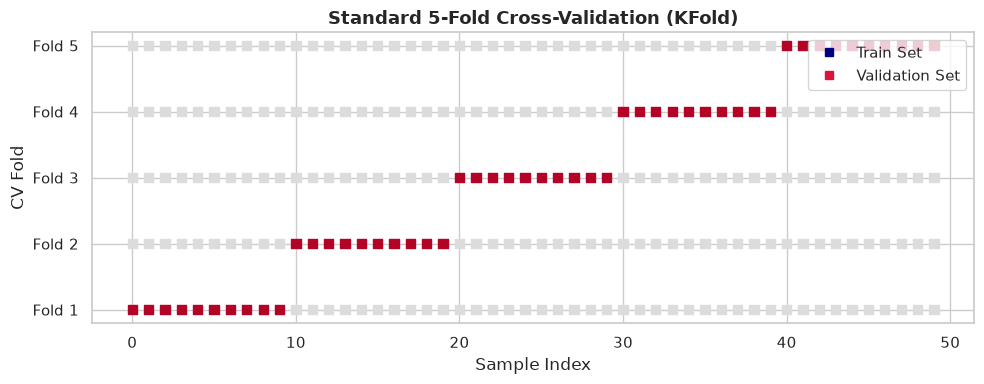

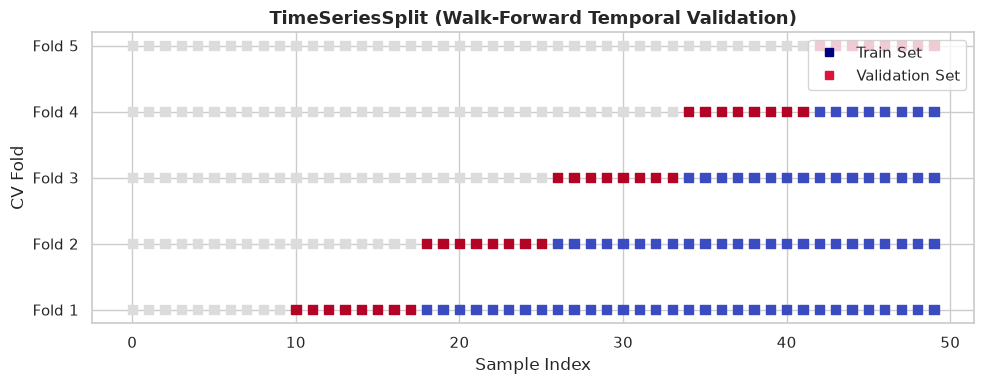

In [2]:
from sklearn.model_selection import (
    KFold, StratifiedKFold, ShuffleSplit, TimeSeriesSplit, GroupKFold, cross_val_score
)

# Visualizing Cross-Validation Splitting Strategies
def plot_cv_splits(cv_iterator, X_len, groups=None, y=None, title="CV Split Strategy"):
    fig, ax = plt.subplots(figsize=(10, 4))
    n_splits = cv_iterator.get_n_splits(X=np.zeros(X_len), y=y, groups=groups)
    
    for fold_idx, (train_idx, val_idx) in enumerate(cv_iterator.split(np.zeros(X_len), y, groups)):
        indices = np.zeros(X_len)
        indices[train_idx] = 1  # 1: Train
        indices[val_idx] = 2    # 2: Validation
        
        ax.scatter(range(X_len), [fold_idx] * X_len, c=indices,
                   marker='s', s=45, cmap=plt.cm.coolwarm, vmin=0, vmax=2)
                   
    ax.set_yticks(range(n_splits))
    ax.set_yticklabels([f"Fold {i+1}" for i in range(n_splits)])
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel("Sample Index")
    ax.set_ylabel("CV Fold")
    # Custom legend
    ax.plot([], [], 's', color='navy', label='Train Set')
    ax.plot([], [], 's', color='crimson', label='Validation Set')
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

# Demonstrate KFold vs StratifiedKFold vs TimeSeriesSplit
X_samples = 50
plot_cv_splits(KFold(n_splits=5), X_samples, title="Standard 5-Fold Cross-Validation (KFold)")
plot_cv_splits(TimeSeriesSplit(n_splits=5), X_samples, title="TimeSeriesSplit (Walk-Forward Temporal Validation)")

10-Fold Stratified Cross-Validation Multi-Metric Evaluation:
   Metric  Test Mean  Test Std  Train Mean  Train Std
 Accuracy   0.978947  0.021912    0.988284   0.001950
Precision   0.975941  0.024773    0.985829   0.002017
   Recall   0.991667  0.017786    0.995644   0.002061
 F1-Score   0.983557  0.017122    0.990711   0.001541
  ROC-AUC   0.996429  0.005798    0.997167   0.000686


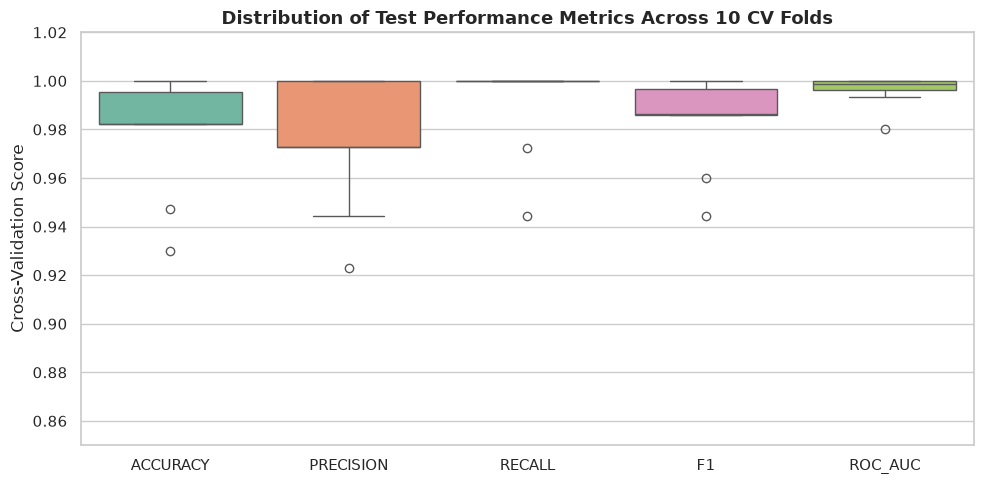

In [3]:
from sklearn.model_selection import cross_validate

# Multi-Metric Evaluation using cross_validate on Breast Cancer Dataset
bc = load_breast_cancer()
X_bc = StandardScaler().fit_transform(bc.data)
y_bc = bc.target

# Define classifier
clf_bc = LogisticRegression(C=0.5, random_state=2024, max_iter=500)

# Configure multi-metric scoring dictionary
scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

# Run Stratified 10-Fold Cross-Validation returning train and test scores
cv_results = cross_validate(
    clf_bc, X_bc, y_bc,
    cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=2024),
    scoring=scoring_metrics,
    return_train_score=True,
    n_jobs=1
)

# Extract scores into DataFrame
df_scores = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Test Mean': [cv_results[f'test_{m}'].mean() for m in scoring_metrics.keys()],
    'Test Std': [cv_results[f'test_{m}'].std() for m in scoring_metrics.keys()],
    'Train Mean': [cv_results[f'train_{m}'].mean() for m in scoring_metrics.keys()],
    'Train Std': [cv_results[f'train_{m}'].std() for m in scoring_metrics.keys()]
})

print("10-Fold Stratified Cross-Validation Multi-Metric Evaluation:")
print(df_scores.to_string(index=False))

# Plot Test Score Distributions Across the 10 Folds
df_fold_dist = pd.DataFrame({m.upper(): cv_results[f'test_{m}'] for m in scoring_metrics.keys()})
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_fold_dist, palette='Set2')
plt.title("Distribution of Test Performance Metrics Across 10 CV Folds", fontsize=13, fontweight='bold')
plt.ylabel("Cross-Validation Score")
plt.ylim(0.85, 1.02)
plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from scipy.stats import uniform, randint
import time

# Model Selection: Exhaustive GridSearchCV vs RandomizedSearchCV
rf_model = RandomForestClassifier(random_state=2024)

# Grid Search parameter grid
grid_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10]
}

# Randomized Search parameter distributions
dist_params = {
    'n_estimators': randint(30, 250),
    'max_depth': [3, 5, 10, 15, None],
    'min_samples_split': randint(2, 12)
}

# 1. Execute GridSearchCV
t0 = time.time()
grid_search = GridSearchCV(rf_model, grid_params, cv=5, scoring='roc_auc', n_jobs=1)
grid_search.fit(X_bc, y_bc)
grid_time = time.time() - t0

# 2. Execute RandomizedSearchCV (20 iterations)
t0 = time.time()
random_search = RandomizedSearchCV(rf_model, dist_params, n_iter=20, cv=5, scoring='roc_auc', random_state=2024, n_jobs=1)
random_search.fit(X_bc, y_bc)
rand_time = time.time() - t0

print("Hyperparameter Optimization Comparison:")
print(f" - GridSearchCV:     Best AUC = {grid_search.best_score_:.4f} (Fit Time: {grid_time:.2f}s, Combinations: {len(grid_search.cv_results_['params'])})")
print(f" - RandomizedSearchCV: Best AUC = {random_search.best_score_:.4f} (Fit Time: {rand_time:.2f}s, Combinations: 20)")
print(f"Optimal RandomSearch Params: {random_search.best_params_}")

Hyperparameter Optimization Comparison:
 - GridSearchCV:     Best AUC = 0.9921 (Fit Time: 28.86s, Combinations: 36)
 - RandomizedSearchCV: Best AUC = 0.9920 (Fit Time: 17.09s, Combinations: 20)
Optimal RandomSearch Params: {'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 141}


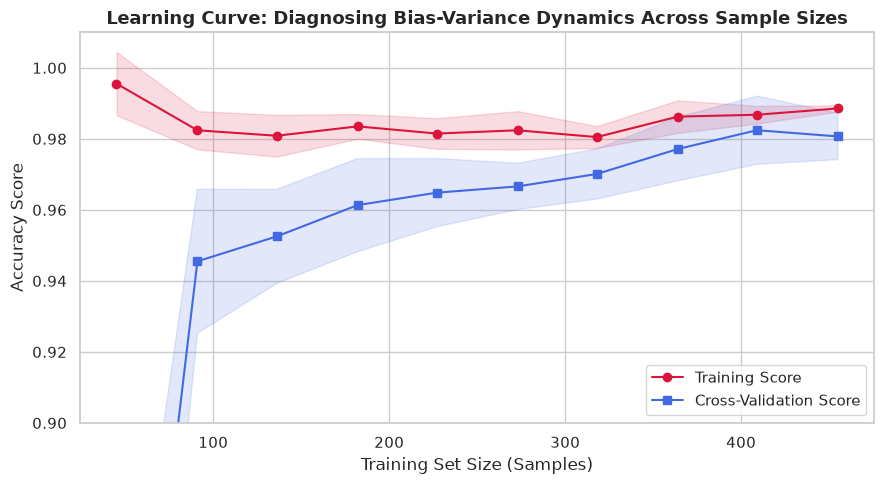

In [5]:
from sklearn.model_selection import learning_curve

# Assessing Model Generalization: Learning Curves
train_sizes, train_scores, test_scores = learning_curve(
    clf_bc, X_bc, y_bc,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5, scoring='accuracy', n_jobs=1, random_state=2024
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_mean, 'o-', color='crimson', label='Training Score')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='crimson')

plt.plot(train_sizes, test_mean, 's-', color='royalblue', label='Cross-Validation Score')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15, color='royalblue')

plt.title("Learning Curve: Diagnosing Bias-Variance Dynamics Across Sample Sizes", fontsize=13, fontweight='bold')
plt.xlabel("Training Set Size (Samples)")
plt.ylabel("Accuracy Score")
plt.ylim(0.90, 1.01)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

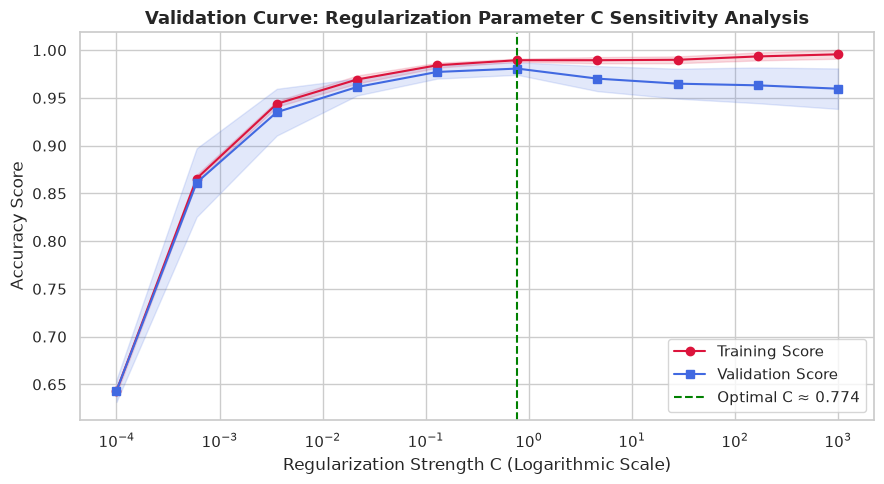

In [6]:
from sklearn.model_selection import validation_curve

# Assessing Hyperparameter Sensitivity: Validation Curves
c_param_range = np.logspace(-4, 3, 10)
train_scores_val, test_scores_val = validation_curve(
    LogisticRegression(max_iter=500, random_state=2024),
    X_bc, y_bc,
    param_name="C",
    param_range=c_param_range,
    cv=5, scoring="accuracy", n_jobs=1
)

train_mean_v = np.mean(train_scores_val, axis=1)
train_std_v = np.std(train_scores_val, axis=1)
test_mean_v = np.mean(test_scores_val, axis=1)
test_std_v = np.std(test_scores_val, axis=1)

plt.figure(figsize=(9, 5))
plt.semilogx(c_param_range, train_mean_v, 'o-', color='crimson', label='Training Score')
plt.fill_between(c_param_range, train_mean_v - train_std_v, train_mean_v + train_std_v, alpha=0.15, color='crimson')

plt.semilogx(c_param_range, test_mean_v, 's-', color='royalblue', label='Validation Score')
plt.fill_between(c_param_range, test_mean_v - test_std_v, test_mean_v + test_std_v, alpha=0.15, color='royalblue')

plt.axvline(x=c_param_range[np.argmax(test_mean_v)], color='green', linestyle='--', label=f'Optimal C ≈ {c_param_range[np.argmax(test_mean_v)]:.3f}')
plt.title("Validation Curve: Regularization Parameter C Sensitivity Analysis", fontsize=13, fontweight='bold')
plt.xlabel("Regularization Strength C (Logarithmic Scale)")
plt.ylabel("Accuracy Score")
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [7]:
# Practical Exercises: Cross-Validation & Generalization Assessment
# Exercise 1: Multiclass Cross-Validation on Iris Dataset
iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)
y_iris = iris.target

cv_iris = cross_val_score(
    LogisticRegression(max_iter=500, random_state=2024),
    X_iris, y_iris,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=2024),
    scoring='accuracy'
)

print("Exercise 1: 5-Fold Stratified CV Accuracy on 3-Class Iris Dataset:")
for fold_i, score_i in enumerate(cv_iris):
    print(f" - Fold {fold_i+1}: Accuracy = {score_i:.4f}")
print(f"Aggregate Mean Accuracy: {cv_iris.mean():.4f} (± {cv_iris.std():.4f})\n")

# Exercise 2: GroupKFold Evaluation for Clustered / Identity Data
# Simulate 120 samples belonging to 10 distinct subjects
n_subject_samples = 120
X_subj, y_subj = make_classification(n_samples=n_subject_samples, n_features=10, random_state=2024)
groups_subject = np.repeat(np.arange(10), n_subject_samples // 10)  # 10 subjects, 12 samples each

gkf = GroupKFold(n_splits=5)
gkf_scores = cross_val_score(LogisticRegression(), X_subj, y_subj, groups=groups_subject, cv=gkf)
print("Exercise 2: GroupKFold Cross-Validation (Zero Subject Leakage):")
print(f" - Fold Scores: {[round(s, 3) for s in gkf_scores]}")
print(f" - Group CV Mean Score: {gkf_scores.mean():.4f} (± {gkf_scores.std():.4f})")

Exercise 1: 5-Fold Stratified CV Accuracy on 3-Class Iris Dataset:
 - Fold 1: Accuracy = 0.9667
 - Fold 2: Accuracy = 0.9333
 - Fold 3: Accuracy = 0.9667
 - Fold 4: Accuracy = 1.0000
 - Fold 5: Accuracy = 0.9333
Aggregate Mean Accuracy: 0.9600 (± 0.0249)

Exercise 2: GroupKFold Cross-Validation (Zero Subject Leakage):
 - Fold Scores: [np.float64(0.917), np.float64(0.917), np.float64(0.958), np.float64(0.917), np.float64(0.917)]
 - Group CV Mean Score: 0.9250 (± 0.0167)
